# Figs. 1 and 2: curvature study on hyperbolic space

Code for Figs. 1 and 2 of *Curvature-Independent Regret Bounds for Distributed Online Optimization on Hadamard
Manifolds* (Z. Cai, E. Sahinoglu, S. Shahrampour). D-ROGD and the baselines run on hyperbolic space
$\mathbb{H}^{10}_\kappa$, with every quantity that enters the regret bounds held fixed while only the curvature
changes:

* **D**: $X$ is the geodesic ball of radius $R=2$ around the origin, so $D=4$ for every $\kappa$;
  $\kappa\in\{0,0.25,1,4,9,16\}$, i.e. $\sqrt{\kappa}D\in\{0,2,4,8,12,16\}$ ($\kappa=0$: Euclidean reference).
* **L, mu**: $d(\cdot,S)$ is 1-Lipschitz and $\tfrac12 d^2(\cdot,S)$ is 1-strongly h-convex on every Hadamard manifold.
* **Network**: 8 agents, 4 nearest neighbours (the network of [12]), Metropolis weights.
* **Data**: anchors at fixed positions on one geodesic (identical mutual distances for every $\kappa$);
  observations $S=\mathrm{Exp}_{a_i}(\xi)$ with an isotropic tangent perturbation $|\xi|\sim U[0,0.8]$;
  the same random numbers for every $\kappa$ and every method (paired comparisons).
* **Initial point**: common, on the boundary of $X$.

Baselines: DPRGD and iDPRGD of Chen and Sun [12] with the parameters prescribed by their analysis, iDPRGD with a
tuned consensus step, and the method of [14] (strongly convex case); reference numbers follow the paper. Regret at
horizon $t$ uses the comparator of that horizon (static regret of horizon $t$).

**How to run.** Run all cells. Every task writes its own file under `results/hyperbolic/` and is skipped if that
file exists, so with the results shipped in this repository the runs are skipped and the notebook only redraws the
figures (about two minutes, mostly the growth-rate fits of Section 6). To rerun the experiments, delete or rename
`results/hyperbolic/` first: the full run takes about 5.5 hours on 4 CPU cores (on Kaggle: *Accelerator: None*,
then *Save & Run All*). `QUICK_RUN = True` (with an empty `results/hyperbolic/`) is a smoke test with 3 seeds and
short horizons. Section 5 needs only numpy, scipy, matplotlib and `results/hyperbolic/`, so the figures can also be
redrawn by running Section 5 alone.

**Outputs.** `results/hyperbolic/` (one file per task), `figures/fig1_regret.{pdf,png}` (Fig. 1),
`figures/fig2_baselines_topology.{pdf,png}` (Fig. 2), and in Section 6 the numbers quoted in the paper and in our
response to the reviewers (`figures/summary_hyperbolic.txt`, `figures/growth_fits_hyperbolic.txt`,
`figures/controls_hyperbolic.csv`). The stored outputs of Sections 1-3 are those of the original run (Kaggle,
numpy 2.1.3, 4 cores); the outputs of Sections 4.6, 5 and 6 were regenerated from the saved results.

In [ ]:
import os
for _v in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ.setdefault(_v, '1')        # one BLAS thread per worker process

import glob, json, time, types, zipfile
import multiprocessing as mp
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

QUICK_RUN = False                     # True: 3 seeds and short horizons (smoke test)
JOBS = os.cpu_count() or 1            # worker processes (one task per (kappa, seed))
print('numpy', np.__version__, '| cores:', JOBS)

numpy 2.1.3 | cores: 4


## 1. Library
Manifolds (Euclidean space and the Lorentz model of $\mathbb{H}^d_\kappa$), graphs, theory constants, consensus solvers, the simulation loop and the data generator.

In [ ]:
"""Manifolds used in the experiments.

* Euclidean(d)           : R^d (the kappa = 0 reference).
* Hyperboloid(d, kappa)  : hyperbolic space of curvature -kappa, Lorentz model.
* SPD(p)                 : symmetric positive-definite matrices, affine-invariant
                           metric <U,V>_X = tr(X^-1 U X^-1 V); curvature in [-1/2, 0].

Every method broadcasts over leading dimensions.  ``pdim`` is the number of
trailing axes that index a single point (1 for vectors, 2 for matrices).

Why the Lorentz model: with the diameter of X fixed, raising the curvature pushes
points towards the boundary of the Poincare ball, where float64 loses accuracy
(the README of the first version of this repository, tag v1.0-submission, reports that D = 4 could not be attained
beyond sqrt(kappa) D = 16).  In the Lorentz model distances are computed from the
Lorentzian chord length, which stays accurate, and the time coordinate is
recomputed from the space coordinates after every operation, so iterates never
drift off the manifold.  Distances do not depend on the model, so results are
directly comparable with the original Poincare-ball implementation.
"""

_TINY = 1e-300

class Euclidean:
    pdim = 1

    def __init__(self, d):
        self.d = int(d)
        self.kappa = 0.0  # curvature lower bound -kappa (used by the baselines)

    def _s(self, a):
        a = np.asarray(a, float)
        return a.reshape(a.shape + (1,))

    def origin(self):
        return np.zeros(self.d)

    def exp_origin(self, w):
        return np.array(w, float)

    def transport_from_origin(self, a, w):
        a, w = np.broadcast_arrays(np.asarray(a, float), np.asarray(w, float))
        return w.copy()

    def dist(self, x, y):
        return np.sqrt(np.sum((y - x) ** 2, -1))

    def dist_origin(self, x):
        return np.sqrt(np.sum(np.asarray(x) ** 2, -1))

    def logd(self, x, y):
        v = y - x
        return v, np.sqrt(np.sum(v * v, -1))

    def log(self, x, y):
        return y - x

    def exp(self, x, v):
        return x + v

    def geodesic(self, x, y, f):
        """Point at fraction f of the geodesic from x to y."""
        return x + self._s(f) * (y - x)

    def norm(self, x, v):
        return np.sqrt(np.sum(v * v, -1))

    def inner(self, x, u, v):
        return np.sum(u * v, -1)

    def proj_ball(self, z, R):
        """Metric projection onto the closed ball of radius R around the origin."""
        r = self.dist_origin(z)
        f = np.where(r > R, R / np.maximum(r, _TINY), 1.0)
        return z * self._s(f)

    def frame(self, x):
        return np.eye(self.d)

    def hess_sqdist_factor(self, r):
        """Transverse eigenvalue of the Hessian of 0.5 d^2(., p) at distance r."""
        return np.ones_like(np.asarray(r, float))


class Hyperboloid:
    """H^d with curvature -kappa as {x in R^{d+1}: <x,x>_L = -1/kappa, x_0 > 0}."""

    pdim = 1

    def __init__(self, d, kappa):
        if kappa <= 0:
            raise ValueError("use Euclidean(d) for kappa = 0")
        self.d = int(d)
        self.kappa = float(kappa)
        self.sk = float(np.sqrt(kappa))

    def _s(self, a):
        a = np.asarray(a, float)
        return a.reshape(a.shape + (1,))

    @staticmethod
    def _mink(u, v):
        return -u[..., 0] * v[..., 0] + np.sum(u[..., 1:] * v[..., 1:], -1)

    def _lift(self, xs):
        """Point with the given space coordinates (time coordinate recomputed)."""
        xs = np.asarray(xs, float)
        x0 = np.sqrt(1.0 / self.kappa + np.sum(xs * xs, -1))
        return np.concatenate([x0[..., None], xs], -1)

    def origin(self):
        return self._lift(np.zeros(self.d))

    def exp_origin(self, w):
        """Exp at the origin of the tangent vector with coordinates w in R^d."""
        w = np.asarray(w, float)
        r = np.sqrt(np.sum(w * w, -1))
        a = self.sk * r
        coef = np.where(a > 1e-12, np.sinh(a) / (self.sk * np.maximum(r, _TINY)), 1.0)
        return self._lift(w * coef[..., None])

    def dist_origin(self, x):
        r = np.sqrt(np.sum(np.asarray(x)[..., 1:] ** 2, -1))
        return np.arcsinh(self.sk * r) / self.sk

    def dist(self, x, y):
        # <x-y, x-y>_L = (4/kappa) sinh^2(sqrt(kappa) d / 2): accurate also for
        # nearby points with large coordinates (no arccosh near 1).
        w = y - x
        c2 = np.maximum(self._mink(w, w), 0.0)
        return (2.0 / self.sk) * np.arcsinh(0.5 * self.sk * np.sqrt(c2))

    def logd(self, x, y):
        """(Log_x(y), d(x, y))."""
        x, y = np.broadcast_arrays(x, y)
        w = y - x
        u = w + self.kappa * self._mink(x, w)[..., None] * x  # tangent at x
        c2 = np.maximum(self._mink(w, w), 0.0)
        d = (2.0 / self.sk) * np.arcsinh(0.5 * self.sk * np.sqrt(c2))
        nu = np.sqrt(np.maximum(self._mink(u, u), 0.0))
        f = np.where(nu > 0, d / np.maximum(nu, _TINY), 0.0)
        return u * f[..., None], d

    def log(self, x, y):
        return self.logd(x, y)[0]

    def norm(self, x, v):
        return np.sqrt(np.maximum(self._mink(v, v), 0.0))

    def inner(self, x, u, v):
        return self._mink(u, v)

    def exp(self, x, v):
        x, v = np.broadcast_arrays(x, v)
        r = self.norm(x, v)
        a = self.sk * r
        coef = np.where(a > 1e-12, np.sinh(a) / (self.sk * np.maximum(r, _TINY)), 1.0)
        y = np.cosh(a)[..., None] * x + coef[..., None] * v
        return self._lift(y[..., 1:])

    def geodesic(self, x, y, f):
        """Point at fraction f in [0, 1] of the geodesic from x to y, computed as the
        positive combination (sinh((1-f)a) x + sinh(f a) y) / sinh(a), a = sqrt(k) d(x,y).
        Unlike Exp_x(f Log_x y), this involves no cancellation, which matters at large
        curvature: tangent vectors at points far from the origin have large ambient
        coordinates, and long geodesics amplify their rounding errors exponentially."""
        x, y = np.broadcast_arrays(x, y)
        f = np.asarray(f, float)
        a = self.sk * self.dist(x, y)
        big = a > 1e-6
        sa = np.sinh(np.where(big, a, 1.0))
        c1 = np.where(big, np.sinh((1.0 - f) * a) / sa, 1.0 - f)
        c2 = np.where(big, np.sinh(f * a) / sa, f)
        return self._lift(c1[..., None] * x[..., 1:] + c2[..., None] * y[..., 1:])

    def transport_from_origin(self, a, w):
        """Parallel transport, from the origin to a, of the tangent vector (0, w)."""
        a = np.asarray(a, float)
        w = np.asarray(w, float)
        aw = np.sum(a[..., 1:] * w, -1)
        coef = self.kappa * aw / (1.0 + self.sk * a[..., 0])
        v0 = np.concatenate([np.zeros(w.shape[:-1] + (1,)), w], -1)
        return v0 + coef[..., None] * (self.origin() + a)

    def proj_ball(self, z, R):
        """Metric projection onto the closed geodesic ball of radius R around the origin."""
        zs = z[..., 1:]
        r = np.sqrt(np.sum(zs * zs, -1))
        d = np.arcsinh(self.sk * r) / self.sk
        f = np.where(d > R, np.sinh(self.sk * R) / (self.sk * np.maximum(r, _TINY)), 1.0)
        return self._lift(zs * f[..., None])

    def frame(self, x):
        """Orthonormal basis of T_x (rows): the standard basis transported from the origin."""
        return self.transport_from_origin(np.asarray(x)[None, :], np.eye(self.d))

    def hess_sqdist_factor(self, r):
        """Transverse eigenvalue sqrt(k) r coth(sqrt(k) r) of Hess 0.5 d^2(., p)."""
        a = self.sk * np.asarray(r, float)
        return np.where(a > 1e-8, a / np.tanh(np.maximum(a, 1e-300)), 1.0)

In [ ]:
"""Communication graphs and Metropolis weights.

Metropolis rule: w_ij = 1 / (1 + max(deg_i, deg_j)) for neighbours i != j and
w_ii = 1 - sum_{j != i} w_ij.  The resulting W is symmetric and doubly
stochastic, and each agent only needs its own degree and its neighbours' degrees.
"""


def is_connected(A):
    n = A.shape[0]
    seen = np.zeros(n, bool)
    stack = [0]
    seen[0] = True
    while stack:
        i = stack.pop()
        for j in np.nonzero(A[i])[0]:
            if not seen[j]:
                seen[j] = True
                stack.append(j)
    return bool(seen.all())


def circulant(n, k):
    """Ring in which every agent is linked to its k nearest neighbours on each side."""
    A = np.zeros((n, n), int)
    for i in range(n):
        for s in range(1, k + 1):
            A[i, (i + s) % n] = A[(i + s) % n, i] = 1
    return A


def complete(n):
    return np.ones((n, n), int) - np.eye(n, dtype=int)


def path(n):
    A = np.zeros((n, n), int)
    for i in range(n - 1):
        A[i, i + 1] = A[i + 1, i] = 1
    return A


def erdos_renyi(n, p, seed=0):
    rng = np.random.default_rng(seed)
    while True:
        U = np.triu(rng.random((n, n)) < p, 1)
        A = (U | U.T).astype(int)
        if is_connected(A):
            return A


def random_geometric(n, radius, seed=0):
    """Random geometric graph on [0,1]^2 (standard sensor-network model)."""
    rng = np.random.default_rng(seed)
    while True:
        P = rng.random((n, 2))
        Dm = np.linalg.norm(P[:, None] - P[None], axis=-1)
        A = ((Dm < radius) & ~np.eye(n, dtype=bool)).astype(int)
        if is_connected(A):
            return A


def metropolis(A):
    A = np.asarray(A, int)
    n = A.shape[0]
    deg = A.sum(1)
    W = np.zeros((n, n))
    I, J = np.nonzero(A)
    W[I, J] = 1.0 / (1.0 + np.maximum(deg[I], deg[J]))
    W[np.arange(n), np.arange(n)] = 1.0 - W.sum(1)
    return W


def sigma2(W):
    """Second-largest singular value; for symmetric W equals max(|lambda_2|, |lambda_n|)."""
    s = np.sort(np.abs(np.linalg.eigvalsh(W)))[::-1]
    return float(s[1])


def make_graph(name, n, seed=0, radius=0.5):
    """'ring' (2 neighbours), 'knn4' (4 nearest neighbours, the network of [12]),
    'complete', 'path', 'er' (p = 0.5), 'rgg' (random geometric graph with the given radius)."""
    if name == 'ring':
        A = circulant(n, 1)
    elif name == 'knn4':
        A = circulant(n, 2)
    elif name == 'complete':
        A = complete(n)
    elif name == 'path':
        A = path(n)
    elif name == 'er':
        A = erdos_renyi(n, 0.5, seed)
    elif name == 'rgg':
        A = random_geometric(n, radius, seed)
    else:
        raise ValueError(name)
    W = metropolis(A)
    return W, sigma2(W)

In [ ]:
"""Curvature constants, baseline parameters and regret bounds.

All curvature-dependent parameters used anywhere in the experiments are computed
here, so that their values can be listed in the response letter.

References (numbering of the paper):
[12] Chen & Sun, Decentralized online Riemannian optimization with dynamic
     environments (DPRGD, iDPRGD).
[14] Cai, Sahinoglu & Shahrampour, Decentralized online Riemannian optimization
     for strongly geodesically convex functions.
"""


def zeta(kappa, c):
    """zeta(kappa, c) = sqrt(kappa) c coth(sqrt(kappa) c), with zeta = 1 for kappa c = 0."""
    x = np.sqrt(kappa) * c
    return 1.0 if x == 0 else float(x / np.tanh(x))


# ------------------------------------------------------------- baselines of [12]
def dprgd_cor7(D, L, kappa, sigma, n, T):
    """Constant step of DPRGD from [12, Cor. 7] with P_T = 0:
    eta = D / sqrt(T C'),  C' = L^2 zeta(kappa, D + L) + 2 sigma sqrt(n) L^2 / (1 - sigma)."""
    Cp = L ** 2 * zeta(kappa, D + L) + 2.0 * sigma * np.sqrt(n) * L ** 2 / (1.0 - sigma)
    return min(1.0, D / np.sqrt(T * Cp))


def idprgd_cor12(D, L, kappa, sigma, n, T):
    """iDPRGD of [12]: consensus step gamma = 1/(2 C3), C3 = zeta(kappa, 2D) (Lemma 8),
    and constant step eta = D / sqrt(2 C4 T) (Cor. 12, P_T = 0) with
    C4 = 8 C3 sqrt(n) L^2 / (1 - sigma) + zeta(kappa, 2D + L) L^2 / 2."""
    C3 = zeta(kappa, 2 * D)
    C4 = 8.0 * C3 * np.sqrt(n) * L ** 2 / (1.0 - sigma) + zeta(kappa, 2 * D + L) * L ** 2 / 2.0
    return min(1.0, D / np.sqrt(2.0 * C4 * T)), 1.0 / (2.0 * C3)


# ---------------------------------------------------------------- baseline of [14]
def cai12(D, L, kappa, mu, T):
    """[14] on a Hadamard manifold: consensus step s = C2/(2 C1) with C1 = zeta(kappa, D),
    C2 = 1, and gradient steps eta_t = 1/(mu t + L/D)."""
    t = np.arange(1, T + 1)
    return 1.0 / (mu * t + L / D), 1.0 / (2.0 * zeta(kappa, D))


# ------------------------------------------------------- bounds of the revised paper
def bound_hconvex(eta, L, D, sigma):
    """Theorem 3.2 for a nonincreasing schedule eta[0..T-1]:
    2 L^2 sigma/(1-sigma) sum_{t<T} eta_t + L^2/2 sum_t eta_t + D^2/(2 eta_T)."""
    eta = np.asarray(eta, float)
    return (2.0 * L ** 2 * sigma / (1.0 - sigma) * eta[:-1].sum()
            + 0.5 * L ** 2 * eta.sum() + D ** 2 / (2.0 * eta[-1]))


def bound_strong(L, mu, sigma, T):
    """Theorem 3.4 with eta_t = 1/(mu t): (2 L^2 sigma/(1-sigma) + L^2/2)(1 + log T)/mu."""
    return (2.0 * L ** 2 * sigma / (1.0 - sigma) + 0.5 * L ** 2) * (1.0 + np.log(T)) / mu


def inexact_extra(eps, eta, L, D, sigma):
    """Additional term E_T of Proposition 3.6 for consensus errors eps[0..T-1].

    The eps^2/2 term, absent from (22), also covers consensus outputs outside X;
    it is negligible for the tolerances used here."""
    eps = np.asarray(eps, float)
    eta = np.asarray(eta, float)
    return 2.0 * L / (1.0 - sigma) * eps[:-1].sum() + np.sum((D * eps + 0.5 * eps ** 2) / eta)

In [ ]:
"""Consensus solvers, comparators and diagnostics.

Consensus (line 6 of Algorithm 1).  Agent i computes
    x_i = argmin_z F_i(z),   F_i(z) = 1/2 sum_j W_ij d^2(z, y_j),
by Riemannian gradient descent started at its own point y_i.  F_i is 1-strongly
g-convex on a Hadamard manifold, hence
    d(z, x_i^e) <= ||grad F_i(z)||,
so stopping when ||grad F_i|| <= eps returns a point within distance eps of the
exact weighted Frechet mean: eps is exactly the eps_t of Proposition 3.6.  Steps
start at 1 (= Karcher iteration) and are halved until an Armijo condition holds;
no curvature information is needed.

The closed-form consensus of [12] (eq. (7)) and [14] (step (II)),
    x_i = Exp_{y_i}(gamma sum_j W_ij Log_{y_i}(y_j)),
is one gradient step on the same F_i with step gamma started at y_i, so both
consensus types share the same code path.
"""


def _contract(W, L):
    """G_i = sum_j W_ij L_ij for L of shape (n, n, *point)."""
    return np.einsum('ij,ij...->i...', W, L)


def _scale(a, X, pdim):
    a = np.asarray(a, float)
    return a.reshape(a.shape + (1,) * pdim) * X


def fm_consensus(M, Y, W, tol=1e-9, max_iter=2000, c=0.25, max_halvings=60, stall=50):
    """Weighted Frechet means of all agents to accuracy tol (distance).

    Riemannian gradient descent on F_i from y_i with Armijo backtracking.  The first
    trial step of each iteration is min(1, 2 a_prev), where a_prev is the step
    accepted in the previous iteration: the solver learns a step of order
    1/zeta(kappa, r), r being the spread of the averaged points, without being told
    the curvature.  When the points are close (the usual case after the first rounds),
    the unit step, i.e. the Karcher iteration, is accepted at every iteration.

    If the gradient norm of an agent has not improved by 1% over `stall` accepted
    iterations, the agent stops: its accuracy has reached the float64 floor, which
    only happens when the averaged points are very far apart at large curvature
    (e.g. sqrt(kappa) x spread = 16 in the first round).  The returned gradient norm
    is then the attained accuracy, covered by Proposition 3.6.

    Returns (Z, iters, evals, gnorm): solution, accepted steps per agent, number of
    objective/gradient evaluations per agent, final gradient norms."""
    n = W.shape[0]
    pd = M.pdim
    Z = Y.copy()
    L, Dd = M.logd(Z[:, None], Y[None, :])
    G = _contract(W, L)                      # = -grad F_i
    g = M.norm(Z, G)
    F = 0.5 * np.sum(W * Dd ** 2, 1)
    a_prev = np.full(n, 0.5)
    iters = np.zeros(n, int)
    evals = np.ones(n, int)
    best = g.copy()
    since = np.zeros(n, int)
    done = np.zeros(n, bool)
    for _ in range(max_iter):
        act = np.nonzero((g > tol) & ~done)[0]
        if act.size == 0:
            break
        alpha = np.minimum(1.0, 2.0 * a_prev[act])
        pend = np.arange(act.size)
        for _ in range(max_halvings):
            ids = act[pend]
            cand = M.exp(Z[ids], _scale(alpha[pend], G[ids], pd))
            Lc, Dc = M.logd(cand[:, None], Y[None, :])
            Gc = _contract(W[ids], Lc)
            gc = M.norm(cand, Gc)
            Fc = 0.5 * np.sum(W[ids] * Dc ** 2, 1)
            evals[ids] += 1
            armijo = Fc <= F[ids] - c * alpha[pend] * g[ids] ** 2
            # Below round-off the Armijo test is meaningless; accept if the gradient shrinks.
            flat = np.abs(Fc - F[ids]) <= 1e-12 * np.maximum(1.0, F[ids])
            ok = armijo | (flat & (gc < g[ids]))
            acc = ids[ok]
            Z[acc], G[acc], g[acc], F[acc] = cand[ok], Gc[ok], gc[ok], Fc[ok]
            a_prev[acc] = alpha[pend][ok]
            iters[acc] += 1
            imp = gc[ok] < 0.99 * best[acc]
            best[acc] = np.where(imp, gc[ok], best[acc])
            since[acc] = np.where(imp, 0, since[acc] + 1)
            done[acc] |= since[acc] >= stall
            pend = pend[~ok]
            alpha[pend] *= 0.5
            if pend.size == 0:
                break
        else:  # no acceptable step (numerical floor): stop these agents
            done[act[pend]] = True
    return Z, iters, evals, g


def cf_consensus(M, Y, W, gamma):
    """Closed-form consensus x_i = Exp_{y_i}(gamma sum_j W_ij Log_{y_i} y_j)."""
    L, _ = M.logd(Y[:, None], Y[None, :])
    return M.exp(Y, gamma * _contract(W, L))


# ------------------------------------------------------------------ batch problems
def batch_frechet_mean(M, P, z0, tol=1e-10, max_iter=3000, c=0.25, stall=50):
    """argmin_z 1/(2N) sum_k d^2(z, P_k): RGD with Armijo backtracking, the same step
    memory as fm_consensus, and a stall test (float64 floor for very spread data)."""
    z = np.array(z0, float)

    def evaluate(z):
        L, d = M.logd(z[None], P)
        G = L.mean(0)
        return G, M.norm(z, G), 0.5 * np.mean(d ** 2)

    G, g, F = evaluate(z)
    a_prev, best, since = 0.5, g, 0
    for _ in range(max_iter):
        if g <= tol or since >= stall:
            break
        a = min(1.0, 2.0 * a_prev)
        for _ in range(60):
            zc = M.exp(z, a * G)
            Gc, gc, Fc = evaluate(zc)
            if Fc <= F - c * a * g * g or (abs(Fc - F) <= 1e-13 * max(1.0, F) and gc < g):
                z, G, g, F, a_prev = zc, Gc, gc, Fc, a
                since = 0 if g < 0.99 * best else since + 1
                best = min(best, g)
                break
            a *= 0.5
        else:
            break
    return z, g


def batch_geometric_median(M, P, z0, tol=1e-10, max_iter=3000, stall=50):
    """argmin_z 1/N sum_k d(z, P_k) by a monotone Riemannian Weiszfeld iteration."""
    z = np.array(z0, float)

    def evaluate(z):
        L, d = M.logd(z[None], P)
        keep = d > 1e-14
        inv = np.where(keep, 1.0 / np.maximum(d, 1e-300), 0.0)
        v = np.tensordot(inv, L, axes=(0, 0)) / inv.sum()   # Weiszfeld step
        return v, M.norm(z, v), np.mean(d)

    v, s, F = evaluate(z)
    best, since = s, 0
    for _ in range(max_iter):
        if s <= tol or since >= stall:
            break
        a = 1.0
        for _ in range(60):
            zc = M.exp(z, a * v)
            vc, sc, Fc = evaluate(zc)
            if Fc < F or (abs(Fc - F) <= 1e-13 * max(1.0, F) and sc < s):
                z, v, s, F = zc, vc, sc, Fc
                since = 0 if s < 0.99 * best else since + 1
                best = min(best, s)
                break
            a *= 0.5
        else:
            break
    return z, s


def log_checkpoints(T, K=30, t_min=10):
    """About K log-spaced horizons in [t_min, T], always including T."""
    ck = np.unique(np.round(np.geomspace(t_min, T, K)).astype(int))
    return ck if ck[-1] == T else np.append(ck, T)


def loss_values(loss, d):
    return d if loss == 'median' else 0.5 * d ** 2


def prefix_comparators(M, S, loss, checkpoints, R):
    """Static regret comparators for every horizon t_k in checkpoints.

    For horizon t the comparator is x*_t = argmin_{x in X} sum_{s<=t} f_s(x), i.e.
    the geometric median / Frechet mean of all n t observations; the function
    returns B[k] = sum_{s<=t_k} f_s(x*_{t_k}), so that Reg(t_k) = A(t_k) - B[k].
    The data lie in the convex set X, hence so does x*_t (checked)."""
    T, n = S.shape[:2]
    P = S.reshape((T * n,) + S.shape[2:])
    z = M.origin()
    B, Z, worst = [], [], 0.0
    solve = batch_geometric_median if loss == 'median' else batch_frechet_mean
    for tk in checkpoints:
        pts = P[: tk * n]
        z, _ = solve(M, pts, z)
        worst = max(worst, float(M.dist_origin(z)) - R)
        B.append(loss_values(loss, M.dist(z[None], pts)).sum() / n)
        Z.append(z.copy())
    if worst > 1e-8:
        print(f"WARNING: comparator outside X by {worst:.2e}; enlarge R")
    return np.array(B), np.array(Z)


def mu_eff(M, z, P):
    """Smallest eigenvalue of the Hessian of 1/(2N) sum_k d^2(., P_k) at z.

    In constant curvature -kappa, Hess 0.5 d^2(., p) has eigenvalue 1 along Log_z p
    and sqrt(kappa) r coth(sqrt(kappa) r) >= 1 in the transverse directions."""
    E = M.frame(z)                                  # (d, ambient) orthonormal basis
    L, r = M.logd(z[None], P)
    keep = r > 1e-12
    U = L[keep] / r[keep, None]
    C = np.array([M.inner(z, U, e) for e in E]).T   # (N, d) coordinates
    phi = M.hess_sqdist_factor(r[keep])
    d = E.shape[0]
    H = (phi[:, None, None] * np.eye(d)[None] + (1.0 - phi)[:, None, None]
         * C[:, :, None] * C[:, None, :]).mean(0)
    return float(np.linalg.eigvalsh(H)[0])

In [ ]:
"""Decentralized online Riemannian gradient methods.

One routine covers every method in the experiments; they differ only in the
step-size sequence and in the consensus step:

  D-ROGD (Algorithm 1)  consensus='fm' : weighted Frechet mean to tolerance tol,
                                          then projection onto X
  DPRGD of [12]         consensus='fm' : same algorithm, step size of [12, Cor. 7]
  iDPRGD of [12]        consensus='cf' : closed-form consensus with step gamma
  method of [14]        consensus='cf' : closed-form consensus with step s

Round t, agent i:  observe S_{i,t};  y_i = P_X(Exp_{x_i}(-eta_t g_i));
                   x_i <- consensus({y_j}).
"""



def _gradient_step(M, X, St, loss, eta):
    """y_i = Exp_{x_i}(-eta g_i) for the local loss l(d(., S_i)); returns (y, |g_i|).

    -g_i points along the geodesic from x_i to S_i (canonical h-subgradient for
    the median, -grad 0.5 d^2 = Log_x S for the mean), so the step is the point at
    fraction eta/d (median) or eta (mean) of that geodesic.  It is evaluated with
    M.geodesic, which is numerically stable at large curvature; a step that
    overshoots S_i (median with eta > d) uses Exp with a unit direction instead."""
    L, d = M.logd(X, St)
    n = d.shape[0]
    if loss == 'mean':
        frac, gnorm = np.full(n, float(eta)), d
    else:
        frac = np.where(d > 0, eta / np.maximum(d, 1e-300), 0.0)
        gnorm = (d > 0).astype(float)
    Y = M.geodesic(X, St, np.minimum(frac, 1.0))
    over = frac > 1.0
    if np.any(over):
        u = L[over] / d[over].reshape((-1,) + (1,) * M.pdim)
        Y[over] = M.exp(X[over], eta * u)
    return Y, gnorm


def run_decentralized(M, S, W, loss, eta, R, x1, consensus='fm', tol=1e-9,
                      gamma=None, project_consensus=None, record=True, track=None):
    """Run one method on the observation stream S (T, n, *point).

    eta : array (T,) of step sizes.   tol : float or array (T,) (D-ROGD only).
    Returns a dict with
      cum_loss   (T,)  A(t) = sum_{s<=t} (1/n) sum_i f_s(x_{i,s})  (f_s = network loss)
      iters      (T,)  mean accepted consensus steps per agent (0 for 'cf': one closed-form step)
      evals      (T,)  mean Log/Exp evaluations of the consensus solver per agent
      t_cons     (T,)  wall-clock time of the consensus step [s]
      disp       (T,)  mean pairwise distance between agents (disagreement)
      spread     (T,)  mean over agents of max_{j,k in N_i} d(y_j, y_k)  (r_t of the cost remark)
      gmax              largest local (sub)gradient norm observed (empirical L)
      track      (T,)  track(X) after every round, if a callable is given
    """
    T, n = S.shape[:2]
    if project_consensus is None:
        project_consensus = consensus == 'fm'
    tol_t = np.broadcast_to(np.asarray(tol, float), (T,))
    X = np.repeat(np.asarray(x1, float)[None], n, 0)
    nb = (W > 0)
    pair_mask = nb[:, :, None] & nb[:, None, :]
    out = {k: np.zeros(T) for k in ('net', 'iters', 'evals', 't_cons', 'disp', 'spread', 'track')}
    gmax = 0.0
    for t in range(T):
        St = S[t]
        # network loss f_t(x_i) = (1/n) sum_j l(d(x_i, S_j)), averaged over agents
        out['net'][t] = loss_values(loss, M.dist(X[:, None], St[None, :])).mean()
        Y, gnorm = _gradient_step(M, X, St, loss, eta[t])
        gmax = max(gmax, float(np.max(gnorm)))
        Y = M.proj_ball(Y, R)
        if record:
            Dy = M.dist(Y[:, None], Y[None, :])
            out['spread'][t] = np.max(np.where(pair_mask, Dy[None], 0.0), axis=(1, 2)).mean()
        t0 = time.perf_counter()
        if consensus == 'fm':
            X, it, ev, _ = fm_consensus(M, Y, W, tol=tol_t[t])
            out['iters'][t], out['evals'][t] = it.mean(), ev.mean()
        elif consensus == 'cf':
            X = cf_consensus(M, Y, W, gamma)
            out['evals'][t] = 1.0
        else:
            raise ValueError(consensus)
        if project_consensus:
            X = M.proj_ball(X, R)
        out['t_cons'][t] = time.perf_counter() - t0
        if record:
            out['disp'][t] = M.dist(X[:, None], X[None, :]).mean()
        if track is not None:
            out['track'][t] = track(X)
    res = {k: v for k, v in out.items() if k != 'net'}
    res['cum_loss'] = np.cumsum(out['net'])
    res['gmax'] = gmax
    res['x_final'] = X
    return res

In [ ]:
"""Observation streams of the two experiments.

Curvature study (fig1_fig2_hyperbolic_curvature.ipynb).  All random numbers are drawn in tangent
coordinates *before* any curvature-dependent map, in the same order for every
kappa, so a given seed produces the same intrinsic data at every curvature
(common random numbers).  What is held fixed across kappa:
  * X = closed geodesic ball of radius R around the origin, so D = 2R;
  * anchors (local data centres) at fixed signed positions on ONE geodesic through
    the origin, so all anchor-to-anchor distances are identical for every kappa
    ('line'); 'random' places them at radius rho_a in random directions, in which
    case their mutual distances grow with kappa (reported, robustness check);
  * observations S = Exp_{a_i}(xi) with xi isotropic in the tangent space at a_i
    (frame transported from the origin) and |xi| ~ U[0, rho_p]: the law of
    d(a_i, S) is the same for every kappa;
  * rho_a + rho_p <= R, so all data lie in X;
  * common initial point on the boundary of X (distance R from the data centre).
'geodesic' puts anchors, observations and the initial point on one geodesic: the
problem is then exactly one-dimensional and the regret must not depend on kappa
(unit test).

Control application (control_application_sensor_network.ipynb): decentralized online
covariance estimation in a sensor network.
Sensor i has true noise covariance Sigma_i = Exp_{Sigma_0}(rho_h U_i); in each
round it forms the sample covariance of m zero-mean Gaussian measurements.  Faulty
sensors report their sample covariance multiplied by `gain`.  X is the geodesic
ball of radius R around the nominal covariance I, which the algorithm knows;
Sigma_0 and Sigma_i are only used to generate data.
"""

def hyperbolic_scenario(kappa, seed, T, n=8, d=10, R=2.0, rho_a=1.2, rho_p=0.8,
                        config='line'):
    rng = np.random.default_rng(seed)
    M = Euclidean(d) if kappa == 0 else Hyperboloid(d, kappa)
    e1 = np.eye(d)[0]
    # ---- anchors (tangent coordinates at the origin), kappa-independent draws
    if config in ('line', 'geodesic'):
        wa = np.linspace(-rho_a, rho_a, n)[:, None] * e1[None]
    elif config == 'random':
        u = rng.standard_normal((n, d))
        wa = rho_a * u / np.linalg.norm(u, axis=1, keepdims=True)
    else:
        raise ValueError(config)
    wa = wa[rng.permutation(n)]          # random assignment of anchors to graph nodes
    # ---- perturbations: |xi| ~ U[0, rho_p], uniform direction
    r = rho_p * rng.random((T, n))
    u = rng.standard_normal((T, n, d))
    u /= np.linalg.norm(u, axis=-1, keepdims=True)
    if config == 'geodesic':
        u = np.sign(u[..., :1]) * e1     # keep only the component along the geodesic
    xi = r[..., None] * u
    # ---- map to the manifold
    anchors = M.exp_origin(wa)
    S = M.exp(anchors[None], M.transport_from_origin(anchors[None], xi))
    x1_dir = e1 if config == 'geodesic' else np.eye(d)[1]
    x1 = M.exp_origin(-R * x1_dir)
    info = dict(anchors=anchors, R=R, D=2 * R, kappa=kappa)
    return M, S, x1, info

In [ ]:
def bin_series(x, nb=50):
    """Means of x over nb log-spaced blocks of rounds (keeps result files small)."""
    T = len(x)
    edges = np.unique(np.round(np.geomspace(1, T + 1, nb + 1)).astype(int))
    mids = np.sqrt(edges[:-1] * np.maximum(edges[1:] - 1, edges[:-1]))
    vals = np.array([x[a - 1:b - 1].mean() for a, b in zip(edges[:-1], edges[1:])])
    return mids, vals


def ci95(a, axis=0):
    """Mean and half-width of the 95% t-confidence interval."""
    a = np.asarray(a, float)
    k = a.shape[axis]
    if k < 2:
        return a.mean(axis), np.zeros_like(a.mean(axis))
    try:
        from scipy.stats import t as student
        q = student.ppf(0.975, k - 1)
    except ImportError:
        q = 1.96
    return a.mean(axis), q * a.std(axis, ddof=1) / np.sqrt(k)


def run_pool(fn, tasks, jobs):
    """Run tasks (each writes its own result file, so interrupted runs resume)."""
    if jobs <= 1 or 'fork' not in mp.get_all_start_methods():
        for k, t in enumerate(tasks):
            print(f"[{k + 1}/{len(tasks)}] {fn(t)}", flush=True)
        return
    with mp.get_context('fork').Pool(jobs) as pool:   # notebook functions are inherited by fork
        for k, r in enumerate(pool.imap_unordered(fn, tasks)):
            print(f"[{k + 1}/{len(tasks)}] {r}", flush=True)


def save_json(obj, path):
    with open(path, 'w') as f:
        json.dump(obj, f, indent=2, sort_keys=True)


def load_json(path):
    with open(path) as f:
        return json.load(f)

## 2. Sanity checks (a few seconds)

In [ ]:
rng = np.random.default_rng(0)


def check(name, ok):
    print(f"[{'ok' if ok else 'FAIL'}] {name}")
    assert ok, name


def rand_pts(M, k, radius):
    w = rng.standard_normal((k, M.d))
    w *= (radius * rng.random((k, 1))) / np.linalg.norm(w, axis=1, keepdims=True)
    return M.exp_origin(w)


for kappa in (0.25, 1.0, 16.0):
    M = Hyperboloid(10, kappa)
    x, y = rand_pts(M, 50, 2.0), rand_pts(M, 50, 2.0)
    v = M.log(x, rand_pts(M, 50, 2.0))
    v = v * (np.minimum(M.norm(x, v), 1.0) / np.maximum(M.norm(x, v), 1e-300))[:, None]
    check(f"H(k={kappa}) d(x, Exp_x v) = |v|", np.allclose(M.dist(x, M.exp(x, v)), M.norm(x, v), atol=1e-9))
    L, d = M.logd(x, y)
    check(f"H(k={kappa}) |Log_x y| = d(x,y)", np.allclose(M.norm(x, L), d, atol=1e-9))
    f = rng.random(50)
    g = M.geodesic(x, y, f)
    check(f"H(k={kappa}) stable geodesic interpolation",
          np.allclose(M.dist(x, g), f * M.dist(x, y), atol=1e-9))
    z = rand_pts(M, 50, 5.0)
    check(f"H(k={kappa}) projection onto the ball",
          np.allclose(M.dist_origin(M.proj_ball(z, 2.0)), np.minimum(M.dist_origin(z), 2.0), atol=1e-9))

W_, _ = make_graph('knn4', 8)
for M in (Hyperboloid(10, 16.0), Euclidean(10)):
    Y = rand_pts(M, 8, 1.0)
    Z, it, ev, g = fm_consensus(M, Y, W_, tol=1e-10)
    check(f"{type(M).__name__}: consensus to tolerance", np.all(g <= 1e-10))
    L0, _ = M.logd(Y[:, None], Y[None])
    check(f"{type(M).__name__}: closed form = one Karcher step",
          np.allclose(cf_consensus(M, Y, W_, 1.0), M.exp(Y, np.einsum('ij,ij...->i...', W_, L0))))

# all data on one geodesic: D-ROGD must coincide for kappa = 0, 1, 16
T_ = 300
for loss, eta in (('median', 1 / np.sqrt(np.arange(1, T_ + 1))), ('mean', 1 / np.arange(1, T_ + 1))):
    A_ = []
    for kappa in (0.0, 1.0, 16.0):
        M, S, x1, info = hyperbolic_scenario(kappa, seed=3, T=T_, config='geodesic')
        A_.append(run_decentralized(M, S, W_, loss, eta, info['R'], x1, tol=1e-12)['cum_loss'])
    check(f"geodesic instance ({loss}): identical for kappa = 0, 1, 16",
          np.allclose(A_[0], A_[1], rtol=1e-8) and np.allclose(A_[0], A_[2], rtol=1e-8))
print('all checks passed')

[ok] H(k=0.25) d(x, Exp_x v) = |v|
[ok] H(k=0.25) |Log_x y| = d(x,y)
[ok] H(k=0.25) stable geodesic interpolation
[ok] H(k=0.25) projection onto the ball
[ok] H(k=1.0) d(x, Exp_x v) = |v|
[ok] H(k=1.0) |Log_x y| = d(x,y)
[ok] H(k=1.0) stable geodesic interpolation
[ok] H(k=1.0) projection onto the ball
[ok] H(k=16.0) d(x, Exp_x v) = |v|
[ok] H(k=16.0) |Log_x y| = d(x,y)
[ok] H(k=16.0) stable geodesic interpolation
[ok] H(k=16.0) projection onto the ball
[ok] Hyperboloid: consensus to tolerance
[ok] Hyperboloid: closed form = one Karcher step
[ok] Euclidean: consensus to tolerance
[ok] Euclidean: closed form = one Karcher step
[ok] geodesic instance (median): identical for kappa = 0, 1, 16
[ok] geodesic instance (mean): identical for kappa = 0, 1, 16
all checks passed


## 3. Configuration and tasks

In [ ]:
CFG = dict(
    kappas=[0.0, 0.25, 1.0, 4.0, 9.0, 16.0],   # sqrt(kappa) D = 0, 2, 4, 8, 12, 16
    n=8, d=10, R=2.0, rho_a=1.2, rho_p=0.8,     # D = 2R = 4 as in the submission
    graph='knn4',                               # network used in the experiments of [12]
    T_med=10000, T_mean=20000, K=30,            # horizons; number of regret checkpoints
    seeds=list(range(100, 130)),                # 30 seeds (the submission used 100-102)
    tune_seeds=[900, 901, 902], T_tune=2000,
    tol=1e-9, mu=1.0,
    gamma_grid=['1/(2zeta)', '1/zeta', 0.25, 0.5, 1.0], c_grid=[1.0],  # tune the consensus step only
    s_grid=['1/(2zeta)', '1/zeta', 0.25, 0.5, 0.8, 1.0],
    tol_kappas=[1.0, 16.0], tol_seeds=list(range(100, 110)),
    topo_kappas=[1.0, 16.0], topo_graphs=['complete', 'er', 'knn4', 'ring', 'path'],
)
QUICK = dict(seeds=[100, 101, 102], T_med=2000, T_mean=4000, K=15, T_tune=1000,
             tune_seeds=[900, 901], tol_seeds=[100, 101, 102])
OUT = os.path.join('results', 'hyperbolic')

cfg = dict(CFG, **(QUICK if QUICK_RUN else {}))
os.makedirs(OUT, exist_ok=True)
save_json(cfg, os.path.join(OUT, 'config.json'))
print({k: cfg[k] for k in ('kappas', 'T_med', 'T_mean', 'K')}, len(cfg['seeds']), 'seeds')

{'kappas': [0.0, 0.25, 1.0, 4.0, 9.0, 16.0], 'T_med': 10000, 'T_mean': 20000, 'K': 30} 30 seeds


In [ ]:
def D_of(cfg):
    return 2.0 * cfg['R']


def _grid_value(v, z):
    return {'1/(2zeta)': 1.0 / (2.0 * z), '1/zeta': 1.0 / z}.get(v, v) if isinstance(v, str) else float(v)


# ------------------------------------------------------------------ method sets
def median_methods(cfg, kappa, T, sigma, tuned=None):
    """h-convex loss d(x, S): L = 1 on every Hadamard manifold."""
    D, L, n = D_of(cfg), 1.0, cfg['n']
    t = np.arange(1, T + 1)
    e7 = dprgd_cor7(D, L, kappa, sigma, n, T)
    e12, g12 = idprgd_cor12(D, L, kappa, sigma, n, T)
    m = {
        'drogd': dict(eta=1.0 / np.sqrt(t), cons='fm'),                   # Theorem 3.2, eta_t = 1/sqrt(t)
        'drogd_T': dict(eta=np.full(T, 1.0 / np.sqrt(T)), cons='fm'),      # Theorem 3.2, eta = 1/sqrt(T)
        'dprgd_c7': dict(eta=np.full(T, e7), cons='fm'),                   # [12], step of Cor. 7
        'idprgd_c12': dict(eta=np.full(T, e12), cons='cf', gamma=g12),     # [12], Lemma 8 + Cor. 12
        'cf_iso': dict(eta=1.0 / np.sqrt(t), cons='cf', gamma=g12),        # only the consensus differs
    }
    if tuned is not None:
        m['idprgd_tuned'] = dict(eta=tuned['c'] / np.sqrt(t), cons='cf', gamma=tuned['gamma'])
    return m


def mean_methods(cfg, kappa, T, sigma, tuned=None):
    """1-strongly h-convex loss 0.5 d^2(x, S): data in X, so |grad| <= D =: L."""
    D, mu = D_of(cfg), cfg['mu']
    L = D
    t = np.arange(1, T + 1)
    eta12, s12 = cai12(D, L, kappa, mu, T)
    m = {
        'drogd': dict(eta=1.0 / (mu * t), cons='fm'),                      # Theorem 3.4
        'cai12': dict(eta=eta12, cons='cf', gamma=s12),                    # [14] with its parameters
    }
    if tuned is not None:
        m['cai12_tuned'] = dict(eta=1.0 / (mu * t), cons='cf', gamma=tuned['s'])  # D-ROGD's steps
    return m


def bounds(cfg, loss, T, sigma):
    D = D_of(cfg)
    if loss == 'median':
        t = np.arange(1, T + 1)
        return {'drogd': bound_hconvex(1.0 / np.sqrt(t), 1.0, D, sigma),
                'drogd_T': bound_hconvex(np.full(T, 1.0 / np.sqrt(T)), 1.0, D, sigma)}
    return {'drogd': bound_strong(D, cfg['mu'], sigma, T)}


def _scenario(cfg, kappa, seed, T, config='line'):
    return hyperbolic_scenario(kappa, seed, T, n=cfg['n'], d=cfg['d'], R=cfg['R'],
                                    rho_a=cfg['rho_a'], rho_p=cfg['rho_p'], config=config)


def _run(M, S, W, loss, spec, cfg, x1, **kw):
    return run_decentralized(M, S, W, loss, spec['eta'], cfg['R'], x1, consensus=spec['cons'],
                             gamma=spec.get('gamma'), tol=kw.pop('tol', cfg['tol']), **kw)


# ------------------------------------------------------------------------ tuning
def task_tune(args):
    cfg, kappa, seed = args
    fn = os.path.join(OUT, f"tune_k{kappa:g}_s{seed}.npz")
    if os.path.exists(fn):
        return fn
    T = cfg['T_tune']
    M, S, x1, _ = _scenario(cfg, kappa, seed, T)
    W, sigma = make_graph(cfg['graph'], cfg['n'])
    D, t = D_of(cfg), np.arange(1, T + 1)
    out = {}
    for loss in ('median', 'mean'):
        B, _ = prefix_comparators(M, S, loss, np.array([T]), cfg['R'])
        if loss == 'median':
            z = zeta(kappa, 2 * D)
            for gi, gv in enumerate(cfg['gamma_grid']):
                for c in cfg['c_grid']:
                    spec = dict(eta=c / np.sqrt(t), cons='cf', gamma=_grid_value(gv, z))
                    r = _run(M, S, W, loss, spec, cfg, x1, record=False)
                    out[f"median_g{gi}_c{c:g}"] = r['cum_loss'][-1] - B[-1]
        else:
            z = zeta(kappa, D)
            for si, sv in enumerate(cfg['s_grid']):     # consensus step only; D-ROGD's steps
                spec = dict(eta=1.0 / (cfg['mu'] * t), cons='cf', gamma=_grid_value(sv, z))
                r = _run(M, S, W, loss, spec, cfg, x1, record=False)
                out[f"mean_s{si}"] = r['cum_loss'][-1] - B[-1]
    np.savez(fn, **out)
    return fn


def select_tuned(cfg):
    D = D_of(cfg)
    tuned = {'median': {}, 'mean': {}}
    for kappa in cfg['kappas']:
        files = [np.load(os.path.join(OUT, f"tune_k{kappa:g}_s{s}.npz")) for s in cfg['tune_seeds']]
        keys = files[0].files
        avg = {k: np.mean([f[k] for f in files]) for k in keys}
        bm = min((k for k in keys if k.startswith('median')), key=avg.get)
        gi, c = bm.split('_')[1:]
        tuned['median'][str(kappa)] = dict(
            gamma=_grid_value(cfg['gamma_grid'][int(gi[1:])], zeta(kappa, 2 * D)),
            c=float(c[1:]), reg=float(avg[bm]))
        bs = min((k for k in keys if k.startswith('mean')), key=avg.get)
        tuned['mean'][str(kappa)] = dict(
            s=_grid_value(cfg['s_grid'][int(bs.split('_s')[1])], zeta(kappa, D)),
            reg=float(avg[bs]))
    save_json(tuned, os.path.join(OUT, 'tuned.json'))
    return tuned


# -------------------------------------------------------------------------- main
def task_main(args):
    cfg, kappa, seed, tuned = args
    fn = os.path.join(OUT, f"main_k{kappa:g}_s{seed}.npz")
    if os.path.exists(fn):
        return fn
    T = max(cfg['T_med'], cfg['T_mean'])
    M, S, x1, info = _scenario(cfg, kappa, seed, T)
    W, sigma = make_graph(cfg['graph'], cfg['n'])
    out = dict(kappa=kappa, seed=seed, sigma=sigma, D=D_of(cfg))
    for loss, Tl, builder in (('median', cfg['T_med'], median_methods),
                              ('mean', cfg['T_mean'], mean_methods)):
        Sl = S[:Tl]
        ck = log_checkpoints(Tl, cfg['K'])
        B, Zs = prefix_comparators(M, Sl, loss, ck, cfg['R'])
        out[f'{loss}_ck'], out[f'{loss}_B'] = ck, B
        tk = tuned[loss].get(str(kappa)) if tuned else None
        for name, spec in builder(cfg, kappa, Tl, sigma, tk).items():
            r = _run(M, Sl, W, loss, spec, cfg, x1)
            key = f'{loss}_{name}'
            out[key + '_reg'] = r['cum_loss'][ck - 1] - B
            for q in ('iters', 'evals', 't_cons', 'disp', 'spread'):
                out[key + '_bin_t'], out[key + '_' + q] = bin_series(r[q])
                out[key + '_' + q + '_mean'] = r[q].mean()
            out[key + '_gmax'] = r['gmax']
            if 'gamma' in spec:
                out[key + '_gamma'] = spec['gamma']
            out[key + '_eta1'] = spec['eta'][0]
        for name, b in bounds(cfg, loss, Tl, sigma).items():
            out[f'{loss}_{name}_bound'] = b
        # --- control quantities (Table in the response letter)
        P = Sl.reshape((-1,) + Sl.shape[2:])
        if loss == 'mean':
            out['mu_eff'] = mu_eff(M, Zs[-1], P)
            out['frechet_var'] = 2.0 * B[-1] / Tl          # mean d^2(S, x*)
        loc = []
        for i in range(cfg['n']):                          # local minimisers x*_i
            solve = batch_geometric_median if loss == 'median' else batch_frechet_mean
            zi, _ = solve(M, Sl[:, i], Zs[-1])
            loc.append(M.dist(zi, Zs[-1]))
        out[f'{loss}_heterogeneity'] = float(np.mean(loc))
    A = info['anchors']
    out['anchor_dist_mean'] = float(M.dist(A[:, None], A[None]).sum() / (cfg['n'] * (cfg['n'] - 1)))
    out['perturbation_mean'] = float(M.dist(A[None], S[:cfg['T_med']]).mean())
    out['data_radius_max'] = float(M.dist_origin(S).max())
    np.savez_compressed(fn, **out)
    return fn


# --------------------------------------------------- growth rates (D-ROGD only)
def task_growth(args):
    """D-ROGD on long horizons with dense checkpoints, for the growth-rate analysis
    (log-log slopes, fit Reg(t) = a + b sqrt(t), regret accumulated after t0)."""
    cfg, kappa, seed = args
    fn = os.path.join(OUT, f"growth_k{kappa:g}_s{seed}.npz")
    if os.path.exists(fn):
        return fn
    T = max(cfg['T_med'], cfg['T_mean'])
    M, S, x1, _ = _scenario(cfg, kappa, seed, T)
    W, sigma = make_graph(cfg['graph'], cfg['n'])
    out = dict(kappa=kappa, seed=seed, sigma=sigma)
    for loss, Tl in (('median', cfg['T_med']), ('mean', cfg['T_mean'])):
        t = np.arange(1, Tl + 1)
        eta = 1.0 / np.sqrt(t) if loss == 'median' else 1.0 / (cfg['mu'] * t)
        ck = log_checkpoints(Tl, 40)
        B, _ = prefix_comparators(M, S[:Tl], loss, ck, cfg['R'])
        r = _run(M, S[:Tl], W, loss, dict(eta=eta, cons='fm'), cfg, x1, record=False)
        out[f'{loss}_ck'], out[f'{loss}_reg'] = ck, r['cum_loss'][ck - 1] - B
    np.savez(fn, **out)
    return fn


# -------------------------------------------------------------- tolerance sweep
TOL_VARIANTS = ['1e-2', '1e-4', '1e-9', 'decay', 'one_step']


def task_tol(args):
    cfg, kappa, seed = args
    fn = os.path.join(OUT, f"tol_k{kappa:g}_s{seed}.npz")
    if os.path.exists(fn):
        return fn
    T = cfg['T_med']
    M, S, x1, _ = _scenario(cfg, kappa, seed, T)
    W, sigma = make_graph(cfg['graph'], cfg['n'])
    t = np.arange(1, T + 1)
    out = dict(kappa=kappa, seed=seed, sigma=sigma)
    for loss in ('median', 'mean'):
        B, _ = prefix_comparators(M, S, loss, np.array([T]), cfg['R'])
        eta = 1.0 / np.sqrt(t) if loss == 'median' else 1.0 / (cfg['mu'] * t)
        for v in TOL_VARIANTS:
            if v == 'one_step':      # a single unit Karcher step = closed-form consensus, gamma = 1
                spec, tol = dict(eta=eta, cons='cf', gamma=1.0), None
            else:
                if v == 'decay':     # rates of Proposition 3.6: eps_t = eps_0/t (h-convex), eps_0/t^2
                    tol = 1e-2 / t if loss == 'median' else 1e-2 / t ** 2
                else:
                    tol = float(v)
                spec = dict(eta=eta, cons='fm')
            r = _run(M, S, W, loss, spec, cfg, x1, tol=cfg['tol'] if tol is None else tol)
            out[f'{loss}_{v}_reg'] = r['cum_loss'][-1] - B[-1]
            out[f'{loss}_{v}_evals'] = r['evals'].sum()
            out[f'{loss}_{v}_iters'] = r['iters'].sum()
            if tol is not None:
                L = 1.0 if loss == 'median' else D_of(cfg)
                eps = np.broadcast_to(np.asarray(tol, float), (T,))
                out[f'{loss}_{v}_ET'] = inexact_extra(eps, eta, L, D_of(cfg), sigma)
    np.savez(fn, **out)
    return fn


# --------------------------------------------------------------------- topology
def task_topology(args):
    cfg, kappa, seed = args
    fn = os.path.join(OUT, f"topo_k{kappa:g}_s{seed}.npz")
    if os.path.exists(fn):
        return fn
    T = cfg['T_med']
    M, S, x1, _ = _scenario(cfg, kappa, seed, T)
    B, _ = prefix_comparators(M, S, 'median', np.array([T]), cfg['R'])
    t = np.arange(1, T + 1)
    out = dict(kappa=kappa, seed=seed)
    for g in cfg['topo_graphs']:
        W, sigma = make_graph(g, cfg['n'], seed=0)
        r = _run(M, S, W, 'median', dict(eta=1.0 / np.sqrt(t), cons='fm'), cfg, x1, record=False)
        out[f'{g}_reg'] = r['cum_loss'][-1] - B[-1]
        out[f'{g}_sigma'] = sigma
    np.savez(fn, **out)
    return fn

## 4. Runs
Order matters only for `tune` (before `main`). Each cell can be rerun; finished tasks are skipped, so with the
shipped results these cells only list the existing files.

In [ ]:
# 4.1 tuned baselines (consensus step only), held-out seeds
run_pool(task_tune, [(cfg, k, s) for k in cfg['kappas'] for s in cfg['tune_seeds']], JOBS)
tuned = select_tuned(cfg)
print(tuned)

In [ ]:
# 4.2 all methods, all curvatures, all seeds
tuned = load_json(os.path.join(OUT, 'tuned.json'))
run_pool(task_main, [(cfg, k, s, tuned) for k in cfg['kappas'] for s in cfg['seeds']], JOBS)

In [ ]:
# 4.3 growth rates: D-ROGD only, long horizons, dense checkpoints
GROWTH_KAPPAS = cfg['kappas']          # e.g. [0.0, 4.0, 16.0] to halve the cost
g_cfg = dict(cfg, T_med=10000, T_mean=20000) if QUICK_RUN else dict(cfg)
run_pool(task_growth, [(g_cfg, k, s) for k in GROWTH_KAPPAS for s in cfg['seeds']], JOBS)

In [ ]:
# 4.4 consensus tolerance (Proposition 3.6) and one-step consensus
run_pool(task_tol, [(cfg, k, s) for k in cfg['tol_kappas'] for s in cfg['tol_seeds']], JOBS)

In [ ]:
# 4.5 network topologies
run_pool(task_topology, [(cfg, k, s) for k in cfg['topo_kappas'] for s in cfg['seeds']], JOBS)

In [ ]:
# 4.6 rounds 1-10 of D-ROGD, for Fig. 1 (the runs above store regret checkpoints from t = 10 on)
def early_rounds(cfg, kappa, seed, t_e=10):
    """Reg(t), t = 1..t_e, of D-ROGD on the data stream of the main runs (same seed, same horizon)."""
    T = max(cfg['T_med'], cfg['T_mean'])
    M, S, x1, _ = _scenario(cfg, kappa, seed, T)
    W, _ = make_graph(cfg['graph'], cfg['n'])
    t = np.arange(1, t_e + 1)
    reg = {}
    for loss in ('median', 'mean'):
        eta = 1.0 / np.sqrt(t) if loss == 'median' else 1.0 / (cfg['mu'] * t)
        B, _ = prefix_comparators(M, S[:t_e], loss, t, cfg['R'])
        r = _run(M, S[:t_e], W, loss, dict(eta=eta, cons='fm'), cfg, x1, record=False)
        reg[loss] = r['cum_loss'] - B
    return reg


EARLY = os.path.join(OUT, 'early_rounds.npz')
if os.path.exists(EARLY):
    print('found', EARLY)
else:
    kap, seeds = np.array(cfg['kappas'], float), np.array(cfg['seeds'])
    res = {loss: np.zeros((len(kap), len(seeds), 10)) for loss in ('median', 'mean')}
    for ki, k in enumerate(kap):
        for si, s in enumerate(seeds):
            for loss, v in early_rounds(cfg, k, int(s)).items():
                res[loss][ki, si] = v
    np.savez(EARLY, kappas=kap, seeds=seeds, **res)
    print('wrote', EARLY, {loss: v.shape for loss, v in res.items()})

wrote results/hyperbolic/early_rounds.npz {'median': (6, 30, 10), 'mean': (6, 30, 10)}


## 5. Figures of the paper
Fig. 1 (`figures/fig1_regret.pdf`) and Fig. 2 (`figures/fig2_baselines_topology.pdf`), drawn from
`results/hyperbolic/` (files `growth_*`, `main_*`, `topo_*` and `early_rounds.npz`). This section needs only numpy,
scipy and matplotlib and can be run on its own; edit the settings in cell 5.1 and rerun cells 5.3 and 5.4 to
restyle the figures.

In [ ]:
# 5.1 Data, output folder and settings (edit freely) ------------------------------------
import glob, os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import t as student

RESULTS = os.path.join('results', 'hyperbolic')         # growth_*, main_*, topo_* and early_rounds.npz
EARLY = os.path.join(RESULTS, 'early_rounds.npz')
FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)

KAPPAS = [0.0, 0.25, 1.0, 4.0, 9.0, 16.0]
D = 4.0                                      # diameter of X (sqrt(kappa) D is the curvature axis)
BAND = 'ci95'                                # 'ci95' (95% CI of the mean) or 'std' (+/- 1 standard deviation)

plt.rcParams.update({'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
                     'legend.fontsize': 8.5, 'pdf.fonttype': 42})

FIG1 = dict(
    figsize=(9.5, 3.6),
    titles=('(a) h-convex', '(b) strongly h-convex'),
    xlabels=('$t$', '$t$ (logarithmic scale)'),
    ylabel=r'$\mathrm{Reg}(t)-\mathrm{Reg}(1)$',
    legend_title=r'$\sqrt{\kappa}D$',
    legend_loc='upper left', legend_ncol=2,
    cmap='viridis', cmap_range=(0.0, 0.9),   # part of the colormap used for the curves
    log_x=(False, True),                     # logarithmic t-axis per panel
    ylim=(None, (-0.01, 0.30)),
    band_alpha=0.25, linewidth=1.6,
    filename='fig1_regret',
)

FIG2 = dict(
    figsize=(9.5, 3.6),
    titles=('(a)', '(b)'),
    # panel (a): (loss, result key, label, color, marker, filled)
    methods=[('median', 'drogd', 'D-ROGD, our work', 'C0', 'o', True),
             ('median', 'dprgd_c7', 'DPRGD [12], Cor. 7', 'C1', 's', True),
             ('median', 'idprgd_c12', 'iDPRGD [12], Cor. 12', 'C3', 'D', True),
             ('mean', 'drogd', 'D-ROGD, our work', 'C0', 'o', False),
             ('mean', 'cai12', 'Strongly g-convex iDPRGD [14]', 'C4', '^', False)],
    tuned=[('median', 'idprgd_tuned', 'C3'), ('mean', 'cai12_tuned', 'C4')],
    tuned_label='tuned consensus step',
    loss_styles={'median': '-', 'mean': '--'},
    loss_labels={'median': r'h-convex, $\mathrm{Reg}(T)/\sqrt{T}$',
                 'mean': r'strongly h-convex, $\mathrm{Reg}(T)/(1+\log T)$'},
    show_bounds=True, bound_labels=('bound, Thm. 3.2', 'bound, Thm. 3.4'),
    xlabel_a=r'$\sqrt{\kappa}\,D$', ylabel_a='normalized regret', ylim_a=(0.025, 80),
    legend_a=dict(fontsize=7.6, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.2), frameon=False),
    # panel (b): topology study
    topo_kappas=[(1.0, 'C0'), (16.0, 'C3')],
    graphs=['complete', 'knn4', 'er', 'ring', 'path'],
    graph_labels={'complete': 'complete', 'knn4': '4-NN', 'er': 'ER', 'ring': 'ring', 'path': 'path'},
    annotate_kappa=1.0,                      # curve whose points carry the graph names (None: no names)
    # per-graph label placement: (offset in points, horizontal alignment)
    graph_label_pos={'complete': ((10, 8), 'center'),
                     'knn4': ((-2, 8), 'center'), 'er': ((-2, 8), 'center'),
                     'ring': ((-4, 8), 'right'), 'path': ((-4, 18), 'right')},
    xlabel_b=r'$\sigma_2(W)$', ylabel_b=r'$\mathrm{Reg}(T)/\sqrt{T}$ (h-convex)',
    filename='fig2_baselines_topology',
)

In [ ]:
# 5.2 Load the results (a few seconds) ----------------------------------------------
def band(a):
    """Mean and half-width of the shaded band over seeds (axis 0)."""
    a = np.asarray(a, float)
    k = a.shape[0]
    if BAND == 'std':
        return a.mean(0), a.std(0, ddof=1)
    return a.mean(0), student.ppf(0.975, k - 1) * a.std(0, ddof=1) / np.sqrt(k)


def load(prefix, kappa):
    files = sorted(glob.glob(os.path.join(RESULTS, f'{prefix}_k{kappa:g}_s*.npz')))
    return [dict(np.load(f)) for f in files]


early = np.load(EARLY)
growth = {k: load('growth', k) for k in KAPPAS}
main = {k: load('main', k) for k in KAPPAS}
topo = {k: load('topo', k) for k, _ in FIG2['topo_kappas']}


def regret_curves(loss, kappa):
    """Checkpoints from t = 1 and Reg(t) - Reg(1) for every seed (rows)."""
    ki = int(np.argmin(np.abs(early['kappas'] - kappa)))
    seeds = list(early['seeds'])
    G = growth[kappa]
    ck = np.r_[np.arange(1, 10), G[0][f'{loss}_ck']]
    reg = np.array([np.r_[early[loss][ki, seeds.index(int(g['seed'])), :9], g[f'{loss}_reg']] for g in G])
    return ck, reg - reg[:, [0]]


print({k: len(v) for k, v in growth.items()}, 'seeds per curvature')

{0.0: 30, 0.25: 30, 1.0: 30, 4.0: 30, 9.0: 30, 16.0: 30} seeds per curvature


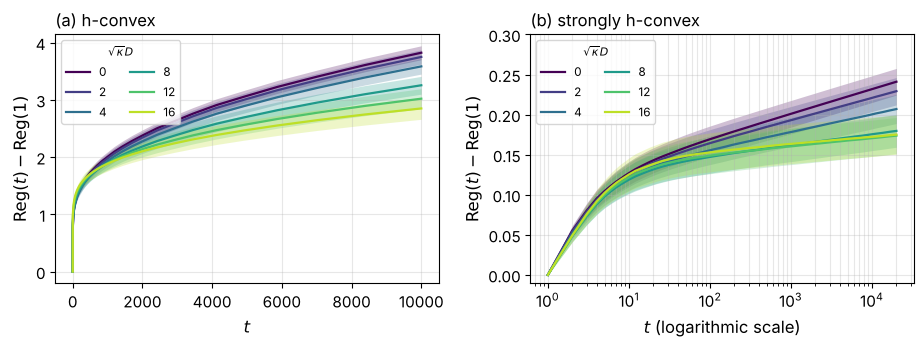

In [ ]:
# 5.3 Fig. 1 ---------------------------------------------------------------------------
def figure1(c=FIG1):
    fig, ax = plt.subplots(1, 2, figsize=c['figsize'])
    colors = plt.get_cmap(c['cmap'])(np.linspace(*c['cmap_range'], len(KAPPAS)))
    for j, loss in enumerate(('median', 'mean')):
        a = ax[j]
        for col, k in zip(colors, KAPPAS):
            ck, y = regret_curves(loss, k)
            m, h = band(y)
            a.plot(ck, m, color=col, lw=c['linewidth'], label=f'{np.sqrt(k) * D:.0f}')
            a.fill_between(ck, m - h, m + h, color=col, alpha=c['band_alpha'], lw=0)
        if c['log_x'][j]:
            a.set_xscale('log')
        if c['ylim'][j] is not None:
            a.set_ylim(*c['ylim'][j])
        a.set_title(c['titles'][j], loc='left')
        a.set_xlabel(c['xlabels'][j])
        a.set_ylabel(c['ylabel'])
        a.grid(alpha=.3, which='both')
        a.legend(title=c['legend_title'], ncol=c['legend_ncol'], loc=c['legend_loc'], title_fontsize=8)
    fig.tight_layout()
    for ext in ('pdf', 'png'):
        fig.savefig(os.path.join(FIG_DIR, f"{c['filename']}.{ext}"), bbox_inches='tight', dpi=200)
    plt.show()


figure1()

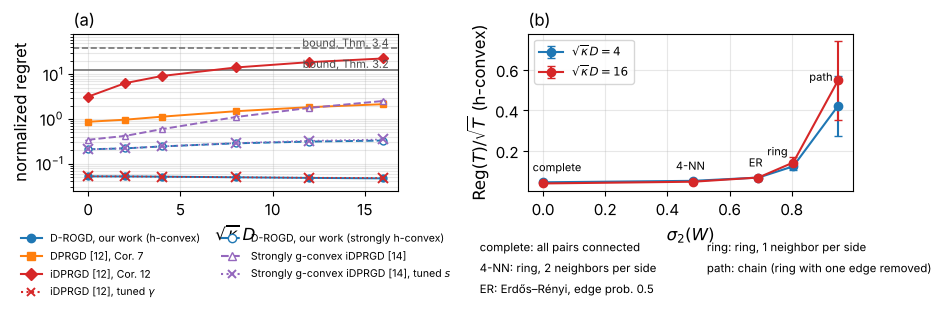

saved
  figures/fig1_regret.pdf
  figures/fig1_regret.png
  figures/fig2_baselines_topology.pdf
  figures/fig2_baselines_topology.png


In [ ]:
# 5.4 Fig. 2 ---------------------------------------------------------------------------
def normalized(loss, key):
    """(mean, band) over seeds of Reg(T)/sqrt(T) (median) or Reg(T)/(1 + log T) (mean), per kappa."""
    out = []
    for k in KAPPAS:
        T = main[k][0][f'{loss}_ck'][-1]
        den = np.sqrt(T) if loss == 'median' else 1 + np.log(T)
        out.append(band(np.array([z[f'{loss}_{key}_reg'][-1] / den for z in main[k]])))
    return np.array(out)


def figure2(c=FIG2):
    fig, ax = plt.subplots(1, 2, figsize=c['figsize'])
    x = np.sqrt(KAPPAS) * D
    a = ax[0]
    for loss, key, lab, col, mk, filled in c['methods']:
        s = normalized(loss, key)
        a.errorbar(x, s[:, 0], yerr=s[:, 1], color=col, marker=mk, ls=c['loss_styles'][loss], ms=5,
                   capsize=2, mfc=col if filled else 'white', lw=1.4)
    for loss, key, col in c['tuned']:
        s = normalized(loss, key)
        # dotted line + crosses, drawn on top, so that it stays visible where it coincides with D-ROGD
        a.plot(x, s[:, 0], ls=':', lw=1.2, marker='x', color=col, ms=7, mew=1.4, zorder=3)
    if c['show_bounds']:
        z0 = main[KAPPAS[0]][0]
        b1 = z0['median_drogd_bound'] / np.sqrt(z0['median_ck'][-1])
        b2 = z0['mean_drogd_bound'] / (1 + np.log(z0['mean_ck'][-1]))
        for b, ls, lab in ((b1, '-', c['bound_labels'][0]), (b2, '--', c['bound_labels'][1])):
            a.axhline(b, color='0.45', lw=1.2, ls=ls)
            a.text(x[-1] + 0.3, b * 1.1, lab, fontsize=8, color='0.3', ha='right')
    a.set_yscale('log')
    a.set_ylim(*c['ylim_a'])
    a.set_xlabel(c['xlabel_a'])
    a.set_ylabel(c['ylabel_a'])
    a.set_title(c['titles'][0], loc='left')
    a.grid(alpha=.3, which='both')
    # one legend entry per curve: h-convex curves in the left column, strongly h-convex in the right
    suffix = {'median': 'h-convex', 'mean': 'strongly h-convex'}
    tuned_labels = {'idprgd_tuned': r'iDPRGD [12], tuned $\gamma$',
                    'cai12_tuned': r'Strongly g-convex iDPRGD [14], tuned $s$'}
    labels = [m[2] for m in c['methods']]
    handles = {'median': [], 'mean': []}
    for loss, _, lab, col, mk, filled in c['methods']:
        name = f'{lab} ({suffix[loss]})' if labels.count(lab) > 1 else lab
        handles[loss].append(Line2D([], [], color=col, marker=mk, ls=c['loss_styles'][loss],
                                    mfc=col if filled else 'white', label=name))
    for loss, key, col in c['tuned']:
        handles[loss].append(Line2D([], [], color=col, marker='x', ls=':', mew=1.4,
                                    label=tuned_labels.get(key, c['tuned_label'])))
    a.legend(handles=handles['median'] + handles['mean'], **c['legend_a'])

    b = ax[1]
    for k, col in c['topo_kappas']:
        Z = topo[k]
        sig = np.array([float(Z[0][g + '_sigma']) for g in c['graphs']])
        T = main[KAPPAS[0]][0]['median_ck'][-1]
        vals = np.array([band(np.array([z[g + '_reg'] / np.sqrt(T) for z in Z])) for g in c['graphs']])
        b.errorbar(sig, vals[:, 0], yerr=vals[:, 1], color=col, marker='o', capsize=3,
                   label=rf'$\sqrt{{\kappa}}D={np.sqrt(k) * D:.0f}$')
        if c['annotate_kappa'] == k:
            for g, s_, v in zip(c['graphs'], sig, vals[:, 0]):
                off, ha = c.get('graph_label_pos', {}).get(g, ((-4, 8), 'right'))
                b.annotate(c['graph_labels'][g], (s_, v), fontsize=8, xytext=off,
                           textcoords='offset points', ha=ha)
    b.set_xlabel(c['xlabel_b'])
    b.set_ylabel(c['ylabel_b'])
    b.set_title(c['titles'][1], loc='left')
    b.grid(alpha=.3)
    b.legend()
    # network definitions below panel (b), next to the legend of panel (a)
    net_text = dict(transform=b.transAxes, ha='left', va='top', fontsize=8.3, linespacing=1.5)
    b.text(-0.15, -0.3, 'complete: all pairs connected\n'
                       '4-NN: ring, 2 neighbors per side\n'
                       'ER: Erdős–Rényi, edge prob. 0.5', **net_text)
    b.text(0.55, -0.3, 'ring: ring, 1 neighbor per side\n'
                        'path: chain (ring with one edge removed)', **net_text)
    fig.tight_layout()
    for ext in ('pdf', 'png'):
        fig.savefig(os.path.join(FIG_DIR, f"{c['filename']}.{ext}"), bbox_inches='tight', dpi=200)
    plt.show()


figure2()
print('saved', *sorted(glob.glob(os.path.join(FIG_DIR, 'fig[12]_*'))), sep='\n  ')

## 6. Numbers quoted in the paper and in the response to the reviewers
Normalized regret of every method, growth rates, cost of the consensus step, control quantities, consensus
tolerance (Proposition 3.6) and network topology (`figures/summary_hyperbolic.txt`,
`figures/controls_hyperbolic.csv`), and growth-rate fits of the regret curves (`figures/growth_fits_hyperbolic.txt`).
Needs Sections 1 and 3.

In [ ]:
# 6.1 Summary ---------------------------------------------------------------------------
SUMMARY_DIR = 'figures'
os.makedirs(SUMMARY_DIR, exist_ok=True)
lines = []


def note(s):
    print(s)
    lines.append(s)


def load_runs(prefix):
    files = sorted(glob.glob(os.path.join('results', 'hyperbolic', f'{prefix}_k*_s*.npz')))
    out = {}
    for f in files:
        z = dict(np.load(f, allow_pickle=True))
        out.setdefault(float(z['kappa']), []).append(z)
    return dict(sorted(out.items()))


def slopes(ck, reg, t_min=100):
    """Least-squares slope of log Reg(t) vs log t over checkpoints t >= t_min (one per seed)."""
    m = (ck >= t_min)
    return np.array([np.polyfit(np.log(ck[m]), np.log(np.maximum(r[m], 1e-12)), 1)[0] for r in reg])


def summary():
    R = load_runs('main')
    cfg = load_json(os.path.join('results', 'hyperbolic', 'config.json'))
    D = 2 * cfg['R']
    kap = np.array(list(R))
    x = np.sqrt(kap) * D
    nseeds = len(next(iter(R.values())))
    note(f"Curvature study: {nseeds} seeds per curvature, sqrt(kappa)D = {x.tolist()}")

    def norm_reg(loss, name):
        """(mean, ci) of Reg(T)/sqrt(T) (median) or Reg(T)/(1+log T) (mean) per kappa."""
        mu, hw = [], []
        for k in kap:
            T = R[k][0][f'{loss}_ck'][-1]
            den = np.sqrt(T) if loss == 'median' else 1 + np.log(T)
            vals = [z[f'{loss}_{name}_reg'][-1] / den for z in R[k] if f'{loss}_{name}_reg' in z]
            if not vals:
                return None
            m, h = ci95(vals)
            mu.append(m)
            hw.append(h)
        return np.array(mu), np.array(hw)

    # normalized regret (Fig. 2(a)); drogd_T: eta = 1/sqrt(T); cf_iso: steps of D-ROGD, consensus of iDPRGD [12]
    for loss, names in (('median', ['drogd', 'drogd_T', 'dprgd_c7', 'idprgd_c12', 'idprgd_tuned', 'cf_iso']),
                        ('mean', ['drogd', 'cai12', 'cai12_tuned'])):
        for nm in names:
            r = norm_reg(loss, nm)
            if r is not None:
                note(f"  {loss:6s} {nm:13s}: " + '  '.join(f'{m:.3f}±{h:.3f}' for m, h in zip(*r))
                     + f"   (x{r[0][-1] / r[0][0]:.2f} from first to last)")
    note(f"  zeta(kappa, D): {np.round([zeta(k, D) for k in kap], 2).tolist()}")

    # growth rates of D-ROGD (main runs)
    for k in kap:
        ck = R[k][0]['median_ck']
        reg = np.array([z['median_drogd_reg'] for z in R[k]])
        s, h = ci95(slopes(ck, reg))
        ck = R[k][0]['mean_ck']
        reg = np.array([z['mean_drogd_reg'] for z in R[k]])
        b = [np.polyfit(np.log(ck[ck >= 100]), r[ck >= 100], 1)[0] for r in reg]
        bm, bh = ci95(b)
        note(f"  growth kappa={k:g}: median log-log slope {s:.3f}±{h:.3f}; "
             f"mean: Reg(t) = a + b log t with b = {bm:.3f}±{bh:.3f}")

    # cost of the consensus step
    for loss in ('median', 'mean'):
        it = [np.mean([z[f'{loss}_drogd_iters_mean'] for z in R[k]]) for k in kap]
        tc = [1e3 * np.mean([z[f'{loss}_drogd_t_cons_mean'] for z in R[k]]) for k in kap]
        cf = 'idprgd_c12' if loss == 'median' else 'cai12'
        tcf = [1e3 * np.mean([z[f'{loss}_{cf}_t_cons_mean'] for z in R[k]]) for k in kap]
        note(f"  cost {loss}: D-ROGD iterations/agent/round {np.round(it, 2).tolist()}; "
             f"consensus time per round [ms] {np.round(tc, 2).tolist()} vs closed form {np.round(tcf, 2).tolist()}")

    # control quantities: constants of the bounds and data geometry for every curvature
    rows = []
    for k, xv in zip(kap, x):
        Z = R[k]
        g = lambda key: np.mean([z[key] for z in Z])
        rows.append(dict(
            sqrt_kappa_D=xv, D=D, L_median=g('median_drogd_gmax'), L_mean=g('mean_drogd_gmax'),
            mu=1.0, mu_eff=g('mu_eff'), perturbation=g('perturbation_mean'),
            anchor_dist=g('anchor_dist_mean'), heterogeneity_median=g('median_heterogeneity'),
            heterogeneity_mean=g('mean_heterogeneity'), frechet_var=g('frechet_var'),
            reg_over_bound_median=np.mean([z['median_drogd_reg'][-1] / z['median_drogd_bound'] for z in Z]),
            reg_over_bound_mean=np.mean([z['mean_drogd_reg'][-1] / z['mean_drogd_bound'] for z in Z]),
            iters_median=g('median_drogd_iters_mean'), iters_mean=g('mean_drogd_iters_mean')))
    keys = list(rows[0])
    with open(os.path.join(SUMMARY_DIR, 'controls_hyperbolic.csv'), 'w') as f:
        f.write(','.join(keys) + '\n')
        for r in rows:
            f.write(','.join(f'{r[k]:.4g}' for k in keys) + '\n')
    note("  controls: " + '; '.join(f"sqrt(k)D={r['sqrt_kappa_D']:.0f}: L_mean={r['L_mean']:.2f}, "
                                     f"mu_eff={r['mu_eff']:.2f}, anchors={r['anchor_dist']:.3f}, "
                                     f"Reg/bound={r['reg_over_bound_median']:.4f}/{r['reg_over_bound_mean']:.4f}"
                                     for r in rows))

    # consensus tolerance (Proposition 3.6) and one-step consensus
    Tt = load_runs('tol')
    variants = ['1e-2', '1e-4', '1e-9', 'decay', 'one_step']
    for loss in ('median', 'mean'):
        for k, Z in Tt.items():
            reg = np.array([[z[f'{loss}_{v}_reg'] for v in variants] for z in Z])
            ev = np.array([[z[f'{loss}_{v}_evals'] for v in variants] for z in Z]).mean(0)
            m, h = ci95(reg / reg[:, [2]])              # paired: relative to tolerance 1e-9
            note(f"  tolerance {loss} kappa={k:g}: Reg(T)/Reg_1e-9 " +
                 ', '.join(f'{v}={mm:.3f}' for v, mm in zip(variants, m)) +
                 ' | evaluations relative to 1e-9: ' + ', '.join(f'{v}={e / ev[2]:.2f}' for v, e in zip(variants, ev)))

    # network topology (Fig. 2(b))
    Tp = load_runs('topo')
    for k, Z in Tp.items():
        gs = [f[:-4] for f in Z[0] if f.endswith('_reg')]
        sig = np.array([float(Z[0][g + '_sigma']) for g in gs])
        T = cfg['T_med']
        m, h = ci95(np.array([[z[g + '_reg'] / np.sqrt(T) for g in gs] for z in Z]))
        o = np.argsort(sig)
        note(f"  topology kappa={k:g}: " + ', '.join(f'{g} (sigma2={s_:.2f}): {mm:.3f}±{hh:.3f}'
                                                   for g, s_, mm, hh in zip(np.array(gs)[o], sig[o], m[o], h[o])))


summary()
with open(os.path.join(SUMMARY_DIR, 'summary_hyperbolic.txt'), 'w') as f:
    f.write('\n'.join(lines) + '\n')

Curvature study: 30 seeds per curvature, sqrt(kappa)D = [0.0, 2.0, 4.0, 8.0, 12.0, 16.0]
  median drogd        : 0.052±0.001  0.052±0.001  0.051±0.001  0.050±0.002  0.048±0.002  0.047±0.002   (x0.90 from first to last)
  median drogd_T      : 1.360±0.002  1.365±0.002  1.399±0.001  1.528±0.001  1.638±0.001  1.713±0.000   (x1.26 from first to last)
  median dprgd_c7     : 0.867±0.001  0.966±0.001  1.128±0.001  1.494±0.001  1.842±0.001  2.148±0.000   (x2.48 from first to last)
  median idprgd_c12   : 3.166±0.003  6.346±0.004  9.188±0.004  14.235±0.004  18.743±0.007  22.666±0.010   (x7.16 from first to last)
  median idprgd_tuned : 0.052±0.001  0.052±0.001  0.051±0.001  0.050±0.002  0.049±0.002  0.048±0.002   (x0.92 from first to last)
  median cf_iso       : 0.097±0.008  0.879±0.094  2.594±0.241  6.792±0.465  10.838±0.550  14.142±0.520   (x146.27 from first to last)
  mean   drogd        : 0.210±0.004  0.220±0.004  0.243±0.004  0.286±0.004  0.312±0.004  0.329±0.005   (x1.57 from first to 

In [ ]:
# 6.2 Growth-rate fits of the regret curves of D-ROGD ---------------------------------------
from scipy.optimize import curve_fit

T0S = (100, 1000)


def lin_fit(xv, y):
    A = np.c_[np.ones_like(xv), xv]
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    res = y - A @ coef
    r2 = 1 - res @ res / np.sum((y - y.mean()) ** 2)
    return coef, r2


def power_fit(t, y):
    try:
        p, _ = curve_fit(lambda t, a, b, q: a + b * t ** q, t, y, p0=(y[0], 0.1, 0.5),
                         bounds=([-np.inf, 0, 0], [np.inf, np.inf, 1.5]), maxfev=20000)
        return p[2]
    except Exception:
        return np.nan


def growth_check():
    files = sorted(glob.glob(os.path.join('results', 'hyperbolic', 'growth_k*_s*.npz')))
    R = {}
    for f in files:
        z = dict(np.load(f))
        R.setdefault(float(z['kappa']), []).append(z)
    R = dict(sorted(R.items()))
    rows = []
    for k, Z in R.items():
        for loss in ('median', 'mean'):
            ck = Z[0][f'{loss}_ck']
            reg = np.array([z[f'{loss}_reg'] for z in Z])
            for t0 in T0S:
                m = ck >= t0
                if m.sum() < 3 or (ck >= 2 * t0).sum() < 3:   # horizon too short for this t0
                    continue
                sl = [np.polyfit(np.log(ck[m]), np.log(r[m]), 1)[0] for r in reg]
                i0 = np.searchsorted(ck, t0)
                mm = ck >= 2 * t0
                dsl = [np.polyfit(np.log(ck[mm] - ck[i0]), np.log(np.maximum(r[mm] - r[i0], 1e-12)), 1)[0]
                       for r in reg]
                bs, r2s, bl, r2l, pp = [], [], [], [], []
                for r in reg:
                    (a, b), r2 = lin_fit(np.sqrt(ck[m]), r[m]); bs.append(b); r2s.append(r2)
                    (a, b), r2 = lin_fit(np.log(ck[m]), r[m]); bl.append(b); r2l.append(r2)
                    pp.append(power_fit(ck[m].astype(float), r[m]))
                rows.append((k, loss, t0, ci95(sl), ci95(dsl), ci95(bs), np.mean(r2s), ci95(bl),
                             np.mean(r2l), ci95(pp)))
    hdr = ('kappa loss t0 | loglog slope | slope of Reg(t)-Reg(t0) | b in a+b*sqrt(t) (R2) '
           '| b in a+b*log(t) (R2) | p in a+b*t^p')
    print(hdr)
    out = [hdr]
    for k, loss, t0, sl, dsl, bs, r2s, bl, r2l, pp in rows:
        line = (f"{k:5g} {loss:6s} {t0:5d} | {sl[0]:.3f}±{sl[1]:.3f} | {dsl[0]:.3f}±{dsl[1]:.3f} | "
                f"{bs[0]:.4f}±{bs[1]:.4f} ({r2s:.4f}) | {bl[0]:.4f}±{bl[1]:.4f} ({r2l:.4f}) | {pp[0]:.2f}±{pp[1]:.2f}")
        print(line)
        out.append(line)
    with open(os.path.join(SUMMARY_DIR, 'growth_fits_hyperbolic.txt'), 'w') as f:
        f.write('\n'.join(out) + '\n')


growth_check()

kappa loss t0 | loglog slope | slope of Reg(t)-Reg(t0) | b in a+b*sqrt(t) (R2) | b in a+b*log(t) (R2) | p in a+b*t^p
    0 median   100 | 0.142±0.002 | 0.581±0.009 | 0.0281±0.0008 (0.9966) | 0.5195±0.0156 (0.9418) | 0.41±0.02
    0 median  1000 | 0.186±0.003 | 0.718±0.011 | 0.0265±0.0006 (0.9990) | 0.7764±0.0164 (0.9806) | 0.44±0.02
    0 mean     100 | 0.006±0.000 | 0.349±0.003 | 0.0005±0.0000 (0.8910) | 0.0135±0.0000 (0.9999) | 0.00±0.00
    0 mean    1000 | 0.006±0.000 | 0.480±0.001 | 0.0004±0.0000 (0.9618) | 0.0134±0.0000 (1.0000) | 0.00±0.00
 0.25 median   100 | 0.138±0.002 | 0.579±0.009 | 0.0275±0.0008 (0.9964) | 0.5079±0.0161 (0.9427) | 0.41±0.02
 0.25 median  1000 | 0.181±0.002 | 0.716±0.011 | 0.0258±0.0006 (0.9990) | 0.7567±0.0168 (0.9808) | 0.44±0.02
 0.25 mean     100 | 0.005±0.000 | 0.348±0.004 | 0.0005±0.0000 (0.8910) | 0.0122±0.0001 (0.9996) | 0.00±0.00
 0.25 mean    1000 | 0.005±0.000 | 0.480±0.005 | 0.0003±0.0000 (0.9616) | 0.0121±0.0001 (0.9996) | 0.01±0.01
    1 media